# 14장. 지능형 판독 시스템 고도화

「AI로 만드는 제조공정 품질관리 따라하기」 14장 실습 Notebook입니다. GPU(T4) 런타임을 쓰세요.
**13장 Notebook을 먼저 실행해야 합니다**(PatchCore 점수·이상 지도를 불러옵니다).

- 데이터: MVTec AD (CC BY-NC-SA 4.0, 비상업적 이용). 결함 마스크를 상자(Bounding Box)로 바꿔 YOLO 라벨로 씁니다
- YOLO: Ultralytics (AGPL-3.0)

실험 설계(결과를 보기 전에 정함)
- 카테고리: bottle, screw, carpet. 13-4와 같은 A/B 분할(평가 이미지를 정상·불량 비율대로 반반)
- YOLO: A의 이미지(불량은 마스크에서 만든 상자, 정상은 배경)로 학습. yolo26n(COCO 사전학습), 640, 100 epoch 고정,
  마지막 가중치, 단일 클래스 "defect". 신뢰도 기준 0.25(기본값)
- PatchCore: 13장 결과(코어셋 10%), 임계값은 A에서 F1 최대
- 평가: B에서 이미지 AUROC, 기준 적용 시 Recall·오검출, 위치 적중, YOLO 상자 mAP50
- 새로운 결함 유형: 결함 종류를 하나씩 빼고 YOLO를 다시 학습해, 뺀 종류를 B에서 얼마나 잡는지 PatchCore와 비교
- 3단계 판정: A에서 두 임계값(미검출 0 / 오검출 0)을 정해 B에 적용 (15개 카테고리, PatchCore)

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    %cd /content/manufacturing-ai-tutorial/03-defect-inspection/inspection-system
    !pip install -q ultralytics==8.4.218

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results/14_runs").mkdir(parents=True, exist_ok=True)

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import roc_auc_score

import src.insp_utils as U

ENV = U.env_info()
print(ENV)

{'python': '3.12.9', 'numpy': '2.5.5', 'pandas': '3.1.1', 'sklearn': '1.9.1', 'opencv': '5.1.0', 'torch': '2.14.1+cu126', 'device': 'NVIDIA GeForce GTX 1080', 'ultralytics': '8.4.218'}


## 14-1. 마스크에서 상자 라벨 만들기

In [3]:
label_stats = {}
for c in U.FOCUS:
    s = U.load_pc_scores(c)
    d = s[s.label == 1]
    nbox = [len(U.mask_to_boxes(U.mask_path(c, p))) for p in d["path"]]
    label_stats[c] = {"defect_images": len(d), "boxes": int(sum(nbox)), "max_boxes_per_image": int(max(nbox)),
                      "multi_box_images": int(sum(n > 1 for n in nbox))}
print(label_stats)

{'bottle': {'defect_images': 63, 'boxes': 68, 'max_boxes_per_image': 3, 'multi_box_images': 4}, 'screw': {'defect_images': 119, 'boxes': 135, 'max_boxes_per_image': 3, 'multi_box_images': 12}, 'carpet': {'defect_images': 89, 'boxes': 97, 'max_boxes_per_image': 3, 'multi_box_images': 7}}


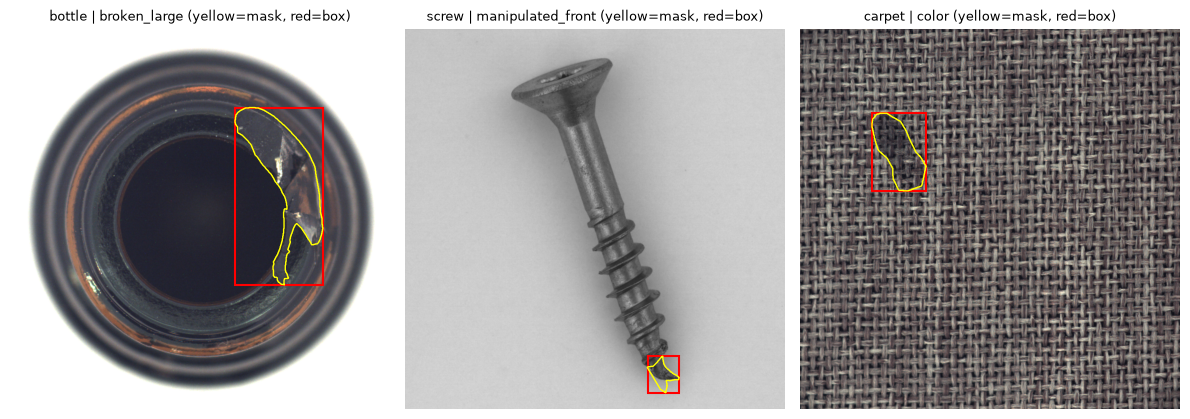

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, c in zip(axes, U.FOCUS):
    s = U.load_pc_scores(c)
    r = s[s.label == 1].iloc[5]
    img = Image.open(U.MVTEC / c / r["path"]).convert("RGB")
    mask = np.asarray(Image.open(U.mask_path(c, r["path"]))) > 0
    ax.imshow(img); ax.contour(mask, levels=[0.5], colors="yellow", linewidths=1)
    w, h = img.size
    for cx, cy, bw, bh in U.mask_to_boxes(U.mask_path(c, r["path"])):
        ax.add_patch(plt.Rectangle(((cx - bw / 2) * w, (cy - bh / 2) * h), bw * w, bh * h, fill=False, color="red", lw=1.5))
    ax.set_title(f"{c} | {r['defect_type']} (yellow=mask, red=box)", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig("results/14_mask_to_box.png", dpi=90); plt.show()

## YOLO 학습과 평가 (카테고리별 전체 학습 + 결함 종류 하나씩 빼고 학습)

끝난 학습은 `results/14_runs/`에 저장하고, 다시 실행하면 건너뜁니다.

In [5]:
U.run_all_jobs_in_subprocesses()                       # 학습은 작업마다 별도 프로세스에서
run_job = U.run_job

full, yolo_b = {}, {}
for c in U.FOCUS:
    full[c], yolo_b[c] = run_job(c)
    print(c, {k: v for k, v in full[c].items() if k not in ("name",)})

bottle {'category': 'bottle', 'exclude': None, 'train_sec': 214.7, 'n_train': 41, 'n_train_defect': 31, 'mAP50': 0.8043, 'mAP50_95': 0.5038, 'box_precision': 0.8709, 'box_recall': 0.7494, 'speed_ms': {'preprocess': 2.14, 'inference': 3.17, 'postprocess': 1.43}}
screw {'category': 'screw', 'exclude': None, 'train_sec': 309.6, 'n_train': 80, 'n_train_defect': 60, 'mAP50': 0.5099, 'mAP50_95': 0.2747, 'box_precision': 0.6582, 'box_recall': 0.5252, 'speed_ms': {'preprocess': 2.92, 'inference': 3.78, 'postprocess': 0.93}}
carpet {'category': 'carpet', 'exclude': None, 'train_sec': 270.0, 'n_train': 58, 'n_train_defect': 44, 'mAP50': 0.8577, 'mAP50_95': 0.4885, 'box_precision': 0.862, 'box_recall': 0.8085, 'speed_ms': {'preprocess': 2.43, 'inference': 4.26, 'postprocess': 1.38}}


## 14-2. 같은 B 이미지에서 YOLO와 PatchCore 비교

In [6]:
rows, hits = [], {}
for c in U.FOCUS:
    s = U.load_pc_scores(c)
    a, b = U.holdout_split(s)
    t_pc = U.f1_threshold(a)
    yb = yolo_b[c].set_index("path").loc[b["path"]].reset_index()
    pc_pred, y_pred = b["score"].to_numpy() >= t_pc, yb["score"].to_numpy() >= U.CONF
    lab = b["label"].to_numpy() == 1
    maps = U.load_pc_maps(c)
    d = b[b.label == 1]
    pc_hit = [U.heatmap_peak_hits_mask(maps[p], U.mask_path(c, p)) for p in d["path"]]
    yb_d = yb[yb.label == 1]
    y_hit = [U.box_hits_mask(bx, U.mask_path(c, p)) for p, bx in zip(yb_d["path"], yb_d["boxes"])]
    for name, score, pred, hit in [("PatchCore", b["score"], pc_pred, pc_hit), ("YOLO", yb["score"], y_pred, y_hit)]:
        rows.append({"category": c, "model": name, "image_AUROC": round(roc_auc_score(lab, score), 4),
                     "recall": round(float(pred[lab].mean()), 3), "fpr": round(float(pred[~lab].mean()), 3),
                     "missed": int((~pred & lab).sum()), "false_alarm": int((pred & ~lab).sum()),
                     "loc_hit": round(float(np.mean(hit)), 3), "B_defect": int(lab.sum()), "B_good": int((~lab).sum())})
compare = pd.DataFrame(rows)
print(compare.to_string(index=False))

category     model  image_AUROC  recall   fpr  missed  false_alarm  loc_hit  B_defect  B_good
  bottle PatchCore       1.0000   1.000 0.000       0            0    0.969        32      10
  bottle      YOLO       1.0000   0.969 0.000       1            0    0.938        32      10
   screw PatchCore       0.9693   0.966 0.238       2            5    0.508        59      21
   screw      YOLO       0.9403   0.678 0.048      19            1    0.678        59      21
  carpet PatchCore       0.9889   0.889 0.000       5            0    0.822        45      14
  carpet      YOLO       0.9746   0.956 0.143       2            2    0.956        45      14


In [7]:
# 결함 종류별 Recall (B): 두 모델이 잘 잡는 종류가 다른가
by_type = []
for c in U.FOCUS:
    s = U.load_pc_scores(c); a, b = U.holdout_split(s); t_pc = U.f1_threshold(a)
    yb = yolo_b[c].set_index("path").loc[b["path"]].reset_index()
    for t in sorted(b.loc[b.label == 1, "defect_type"].unique()):
        m = (b.defect_type == t).to_numpy()
        by_type.append({"category": c, "defect_type": t, "n_B": int(m.sum()),
                        "PatchCore": round(float((b["score"].to_numpy()[m] >= t_pc).mean()), 3),
                        "YOLO": round(float((yb["score"].to_numpy()[m] >= U.CONF).mean()), 3)})
by_type = pd.DataFrame(by_type)
print(by_type.to_string(index=False))

category         defect_type  n_B  PatchCore  YOLO
  bottle        broken_large   11      1.000 1.000
  bottle        broken_small   10      1.000 1.000
  bottle       contamination   11      1.000 0.909
   screw   manipulated_front   12      1.000 0.167
   screw        scratch_head   12      0.917 0.917
   screw        scratch_neck   12      1.000 0.917
   screw         thread_side   11      1.000 0.636
   screw          thread_top   12      0.917 0.750
  carpet               color   11      0.909 1.000
  carpet                 cut    5      1.000 1.000
  carpet                hole    9      1.000 1.000
  carpet metal_contamination    9      0.889 1.000
  carpet              thread   11      0.727 0.818


### 새로운 결함 유형: 학습에서 뺀 종류를 잡을 수 있는가

In [8]:
unseen = []
for c in U.FOCUS:
    s = U.load_pc_scores(c); a, b = U.holdout_split(s); t_pc = U.f1_threshold(a)
    for t in sorted(s.loc[s.label == 1, "defect_type"].unique()):
        out, sc = run_job(c, exclude=t)
        m = (sc.defect_type == t).to_numpy()
        pc_m = (b.defect_type == t).to_numpy()
        good = (sc.label == 0).to_numpy()
        unseen.append({"category": c, "held_out": t, "n_B": int(m.sum()),
                       "YOLO_seen": by_type.query("category == @c and defect_type == @t")["YOLO"].item(),
                       "YOLO_unseen": round(float((sc["score"].to_numpy()[m] >= U.CONF).mean()), 3),
                       "YOLO_unseen_fpr": round(float((sc["score"].to_numpy()[good] >= U.CONF).mean()), 3),
                       "PatchCore": round(float((b["score"].to_numpy()[pc_m] >= t_pc).mean()), 3),
                       "train_sec": out["train_sec"]})
        print(unseen[-1])
unseen = pd.DataFrame(unseen)
print(unseen.to_string(index=False))
print(unseen[["YOLO_seen", "YOLO_unseen", "PatchCore"]].mean().round(3))

{'category': 'bottle', 'held_out': 'broken_large', 'n_B': 11, 'YOLO_seen': 1.0, 'YOLO_unseen': 1.0, 'YOLO_unseen_fpr': 0.0, 'PatchCore': 1.0, 'train_sec': 185.4}
{'category': 'bottle', 'held_out': 'broken_small', 'n_B': 10, 'YOLO_seen': 1.0, 'YOLO_unseen': 0.9, 'YOLO_unseen_fpr': 0.0, 'PatchCore': 1.0, 'train_sec': 173.7}
{'category': 'bottle', 'held_out': 'contamination', 'n_B': 11, 'YOLO_seen': 0.909, 'YOLO_unseen': 0.455, 'YOLO_unseen_fpr': 0.0, 'PatchCore': 1.0, 'train_sec': 171.2}
{'category': 'screw', 'held_out': 'manipulated_front', 'n_B': 12, 'YOLO_seen': 0.167, 'YOLO_unseen': 0.167, 'YOLO_unseen_fpr': 0.0, 'PatchCore': 1.0, 'train_sec': 278.6}
{'category': 'screw', 'held_out': 'scratch_head', 'n_B': 12, 'YOLO_seen': 0.917, 'YOLO_unseen': 0.833, 'YOLO_unseen_fpr': 0.095, 'PatchCore': 0.917, 'train_sec': 282.8}
{'category': 'screw', 'held_out': 'scratch_neck', 'n_B': 12, 'YOLO_seen': 0.917, 'YOLO_unseen': 0.75, 'YOLO_unseen_fpr': 0.0, 'PatchCore': 1.0, 'train_sec': 293.3}
{'cate

{'category': 'carpet', 'held_out': 'hole', 'n_B': 9, 'YOLO_seen': 1.0, 'YOLO_unseen': 1.0, 'YOLO_unseen_fpr': 0.0, 'PatchCore': 1.0, 'train_sec': 240.9}
{'category': 'carpet', 'held_out': 'metal_contamination', 'n_B': 9, 'YOLO_seen': 1.0, 'YOLO_unseen': 1.0, 'YOLO_unseen_fpr': 0.0, 'PatchCore': 0.889, 'train_sec': 239.7}
{'category': 'carpet', 'held_out': 'thread', 'n_B': 11, 'YOLO_seen': 0.818, 'YOLO_unseen': 0.455, 'YOLO_unseen_fpr': 0.0, 'PatchCore': 0.727, 'train_sec': 244.8}
category            held_out  n_B  YOLO_seen  YOLO_unseen  YOLO_unseen_fpr  PatchCore  train_sec
  bottle        broken_large   11      1.000        1.000            0.000      1.000      185.4
  bottle        broken_small   10      1.000        0.900            0.000      1.000      173.7
  bottle       contamination   11      0.909        0.455            0.000      1.000      171.2
   screw   manipulated_front   12      0.167        0.167            0.000      1.000      278.6
   screw        scratch_head  

## 14-3. 처리 시간과 3단계 판정

In [9]:
pc13 = json.loads(Path("../anomaly-detection/results/13_patchcore.json").read_text(encoding="utf-8"))
speed = {"PatchCore 10% (ms/장)": round(float(np.mean([r["ms_10"] for r in pc13["speed"]])), 2),
         "PatchCore 1% (ms/장)": round(float(np.mean([r["ms_1"] for r in pc13["speed"]])), 2),
         "YOLO (ms/장, 전처리+추론+후처리)": round(float(np.mean([sum(full[c]["speed_ms"].values()) for c in U.FOCUS])), 2),
         "YOLO 추론만 (ms/장)": round(float(np.mean([full[c]["speed_ms"]["inference"] for c in U.FOCUS])), 2),
         "YOLO 학습 (초, 평균)": round(float(np.mean([full[c]["train_sec"] for c in U.FOCUS])), 1)}
print(speed)

{'PatchCore 10% (ms/장)': 27.17, 'PatchCore 1% (ms/장)': 7.65, 'YOLO (ms/장, 전처리+추론+후처리)': 7.48, 'YOLO 추론만 (ms/장)': 3.74, 'YOLO 학습 (초, 평균)': 264.8}


In [10]:
three = {}
for c in pd.DataFrame(pc13["table"]).iloc[:, 0]:
    s = U.load_pc_scores(c); a, b = U.holdout_split(s)
    three[c] = U.three_way(a, b)
three_df = pd.DataFrame(three).T
three_df["review_pct"] = (three_df["review"] / three_df["n"] * 100).round(1)
print(three_df.to_string())
tot = three_df[["n", "auto_pass", "review", "auto_ng", "missed_in_pass", "good_in_ng"]].sum()
print("15개 합계:", tot.to_dict(), "| 재검토 비율", round(tot["review"] / tot["n"] * 100, 1), "%")

              t_low   t_high     n  auto_pass  review  auto_ng  missed_in_pass  good_in_ng  review_defect  review_good  review_pct
bottle      32.8887  32.8887  42.0       10.0     0.0     32.0             0.0         0.0            0.0          0.0         0.0
cable       39.9116  43.0646  75.0       17.0    11.0     47.0             0.0         1.0            0.0         11.0        14.7
capsule     25.9079  26.4708  66.0       10.0     1.0     55.0             1.0         2.0            0.0          1.0         1.5
carpet      25.2792  33.3285  59.0        3.0    12.0     44.0             0.0         1.0            2.0         10.0        20.3
grid        31.8527  31.8527  39.0       11.0     0.0     28.0             2.0         2.0            0.0          0.0         0.0
hazelnut    45.5641  45.5641  55.0       20.0     0.0     35.0             0.0         0.0            0.0          0.0         0.0
leather     33.9045  33.9045  62.0       16.0     0.0     46.0             0.0     

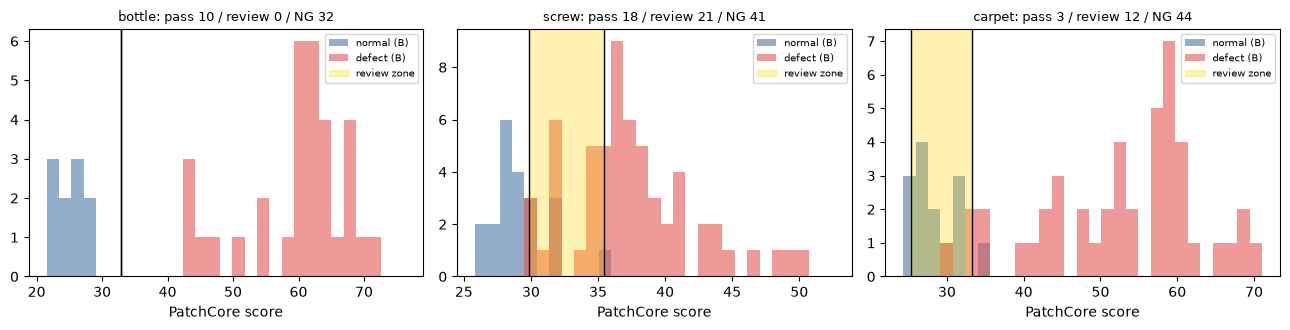

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c in zip(axes, U.FOCUS):
    s = U.load_pc_scores(c); a, b = U.holdout_split(s); r = three[c]
    bins = np.linspace(s.score.min(), s.score.max(), 30)
    ax.hist(b[b.label == 0].score, bins, alpha=0.6, color="#4C78A8", label="normal (B)")
    ax.hist(b[b.label == 1].score, bins, alpha=0.6, color="#E45756", label="defect (B)")
    ax.axvspan(r["t_low"], r["t_high"], color="gold", alpha=0.3, label="review zone")
    ax.axvline(r["t_low"], color="k", lw=1); ax.axvline(r["t_high"], color="k", lw=1)
    ax.set_title(f"{c}: pass {r['auto_pass']} / review {r['review']} / NG {r['auto_ng']}", fontsize=9)
    ax.set_xlabel("PatchCore score"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig("results/14_three_way.png", dpi=100); plt.show()

## 14-4. 판독 화면용 데이터 저장

`app/review_app.py`(Streamlit)가 읽는 파일을 만듭니다.

In [12]:
queue = []
for c in U.FOCUS:
    s = U.load_pc_scores(c); a, b = U.holdout_split(s); r = three[c]
    yb = yolo_b[c].set_index("path")
    for _, row in b.iterrows():
        decision = "자동 통과" if row.score < r["t_low"] else ("자동 불량" if row.score >= r["t_high"] else "재검토")
        queue.append({"category": c, "path": row.path, "defect_type": row.defect_type, "label": int(row.label),
                      "pc_score": round(float(row.score), 3), "yolo_score": round(float(yb.loc[row.path, "score"]), 3),
                      "yolo_boxes": yb.loc[row.path, "boxes"], "decision": decision})
pd.DataFrame(queue).to_csv("results/14_review_queue.csv", index=False)
Path("results/14_thresholds.json").write_text(json.dumps({c: three[c] for c in U.FOCUS}, indent=2), encoding="utf-8")
print(pd.DataFrame(queue).groupby(["category", "decision"]).size())

category  decision
bottle    자동 불량       32
          자동 통과       10
carpet    자동 불량       44
          자동 통과        3
          재검토         12
screw     자동 불량       41
          자동 통과       18
          재검토         21
dtype: int64


In [13]:
out = {"env": ENV, "yolo_cfg": U.YOLO_CFG, "conf": U.CONF, "label_stats": label_stats,
       "full": full, "compare": compare.to_dict("records"), "by_type": by_type.to_dict("records"),
       "unseen": unseen.to_dict("records"), "unseen_mean": unseen[["YOLO_seen", "YOLO_unseen", "PatchCore"]].mean().round(4).to_dict(),
       "speed": speed, "three_way": three, "three_way_total": tot.astype(int).to_dict()}
Path("results/14_inspection.json").write_text(json.dumps(out, ensure_ascii=False, indent=2, default=float), encoding="utf-8")

12450